# 第 18 章：delta 对冲，例 18.1 与例 18.2

第 18.1 节交易商的问题，以及表 18.1 与表 18.2 的两套对冲方案，
逐笔交易地重建出来。

| 节 | 复现什么 |
|---|---|
| 1 | 这个头寸，以及裸头寸与备兑头寸为什么都是赌注 |
| 2 | 每周的方案，以及表 18.1（到期实值） |
| 3 | 表 18.2（到期虚值） |
| 4 | 怎么读它们：例 18.2 的两次往返 |
| 5 | 两笔成本为什么不同：残差，以及它如何随 $n$ 下降 |

股价路径取自正文，作为数据给出。它们是模拟路径，无法由公式复现，
因此本笔记本按正文所印取用，其余各项都重新计算。
**每一个 delta、每一笔股数、两笔对冲成本都是在这里算出来的**，不是抄来的。

只用标准库，外加 NumPy 与 SciPy（仅最后一节用到）。

表头保留英文：中文字符在等宽终端里是双宽的，而 Python 的 `%-40s` 按字符数计。

In [1]:
from math import log, sqrt, exp
from statistics import NormalDist

N = NormalDist().cdf

S0, K, r, SIGMA, WEEKS, N_OPT = 63.0, 64.0, 0.04, 0.22, 18, 100_000


def show(label, got, printed, tol=6e-4):
    """把算出来的值印在本章所印的值旁边。"""
    flag = "ok" if abs(got - printed) <= tol * max(1.0, abs(printed)) else "DIFFERS"
    print("%-42s %14.4f   book %12.4f   %s" % (label, got, printed, flag))


def bs_call(S, K, T, r, sig):
    if T <= 0:
        return max(S - K, 0.0)
    d1 = (log(S / K) + (r + 0.5 * sig * sig) * T) / (sig * sqrt(T))
    return S * N(d1) - K * exp(-r * T) * N(d1 - sig * sqrt(T))


def delta(S, T, K=K, r=r, sig=SIGMA):
    """N(d1)；在到期时就是那条光滑 delta 所收敛到的阶跃函数。"""
    if T <= 0:
        return 1.0 if S > K else 0.0
    return N((log(S / K) + (r + 0.5 * sig * sig) * T) / (sig * sqrt(T)))


T0 = WEEKS / 52.0
price = bs_call(S0, K, T0, r, SIGMA)
premium = price * N_OPT
show("Black-Scholes-Merton price per option", price, 3.1944)
show("premium received", premium, 319438, tol=1e-5)
show("premium compounded to expiration", premium * exp(r * T0), 323900, tol=1e-4)
import matplotlib.pyplot as plt

# The book's figure palette, from preamble.tex: exampleframe for the primary series,
# snapshotframe for the contrast one. Series are distinguished by dash pattern as well as
# color, because the book prints in grayscale.
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

Black-Scholes-Merton price per option              3.1944   book       3.1944   ok
premium received                              319437.8188   book  319438.0000   ok
premium compounded to expiration              323891.5664   book  323900.0000   ok


## 1. 什么都不做与买入股票，都不是对冲

两种替代做法都把交易商的头寸变成一个方向性赌注，只是方向相反，
而每一种都可能亏掉大约两倍的权利金。

In [2]:
print("%19s %16s %16s" % ("stock at expiration", "naked", "covered"))
for S_T in (54.0, 74.0):
    owed = max(S_T - K, 0.0) * N_OPT
    naked = premium - owed
    covered = premium - owed + (S_T - S0) * N_OPT
    print("%19.0f %16s %16s" % (S_T, "{:,.0f}".format(naked), "{:,.0f}".format(covered)))
show("naked, stock at 54", premium, 319438, tol=1e-5)
show("naked, stock at 74", premium - 10.0 * N_OPT, -680562, tol=1e-5)
show("covered, stock at 54", premium - 0 + (54 - 63) * N_OPT, -580562, tol=1e-5)
show("covered, stock at 74", premium - 10.0 * N_OPT + (74 - 63) * N_OPT, 419438, tol=1e-5)

stock at expiration            naked          covered
                 54          319,438         -580,562
                 74         -680,562          419,438
naked, stock at 54                            319437.8188   book  319438.0000   ok
naked, stock at 74                           -680562.1812   book -680562.0000   ok
covered, stock at 54                         -580562.1812   book -580562.0000   ok
covered, stock at 74                          419437.8188   book  419438.0000   ok


## 2. 每周的方案：表 18.1

交易商在第 0 周借款买入 $\Delta \times 100{,}000$ 股，此后每周借入或偿还，
把 delta 中性恢复过来。累计成本这一列把上一周的余额按 4\% 计息，
再加上本周的交易，因此它就是尚未偿还的债务。
到期时以股票交割、收取执行价。

In [3]:
def run_hedge(path, verbose=True):
    """由每周股价路径重建一张对冲表。成本以千美元计。"""
    prev_delta, cum, rows = 0.0, 0.0, []
    for week, S in enumerate(path):
        d = delta(S, (WEEKS - week) / 52.0)
        shares = (d - prev_delta) * N_OPT
        cost = shares * S / 1000.0
        cum = cost if week == 0 else cum + cum * r / 52.0 + cost
        interest = cum * r / 52.0
        rows.append((week, S, d, shares, cost, cum, interest))
        prev_delta = d
    if verbose:
        print("%4s %7s %7s %11s %10s %11s %8s"
              % ("week", "stock", "delta", "shares", "cost", "cumulative", "interest"))
        for w, S, d, sh, c, cu, it in rows:
            print("%4d %7.2f %7.3f %11s %10.1f %11.1f %8.1f"
                  % (w, S, d, "{:,.0f}".format(sh), c, cu, it if w < WEEKS else 0.0))
    return rows


ITM = [63.00, 61.12, 62.51, 60.86, 58.46, 61.57, 62.02, 62.03, 61.55, 63.48,
       61.94, 64.41, 64.71, 63.86, 63.25, 66.43, 70.36, 69.67, 66.04]

rows_itm = run_hedge(ITM)
cost_itm = rows_itm[-1][5] - K * N_OPT / 1000.0        # 行权时交付股票
print()
show("cumulative cost at week 18", rows_itm[-1][5], 6736.8, tol=2e-4)
show("cost of hedging the option, $000", cost_itm, 336.8, tol=2e-3)

week   stock   delta      shares       cost  cumulative interest
   0   63.00   0.520      51,995     3275.7      3275.7      2.5
   1   61.12   0.421      -9,889     -604.4      2673.8      2.1
   2   62.51   0.488       6,651      415.8      3091.6      2.4
   3   60.86   0.394      -9,362     -569.7      2524.2      1.9
   4   58.46   0.261     -13,343     -780.0      1746.1      1.3
   5   61.57   0.418      15,788      972.1      2719.5      2.1
   6   62.02   0.438       1,915      118.8      2840.4      2.2
   7   62.03   0.431        -692      -43.0      2799.6      2.2
   8   61.55   0.391      -3,959     -243.7      2558.1      2.0
   9   63.48   0.513      12,183      773.4      3333.5      2.6
  10   61.94   0.396     -11,724     -726.2      2609.8      2.0
  11   64.41   0.574      17,822     1147.9      3759.8      2.9
  12   64.71   0.597       2,360      152.7      3915.4      3.0
  13   63.86   0.523      -7,417     -473.7      3444.7      2.6
  14   63.25   0.455     

## 3. 同一个头寸，一条到期作废的路径：表 18.2

delta 一路走到零，最后一笔交易把头寸清掉。到期时没有做任何决定：
方案自动收敛到期权的收益，因为 $N(d_1)$ 变成了一个阶跃函数。

In [4]:
OTM = [63.00, 61.60, 63.45, 61.36, 61.57, 61.08, 59.75, 58.01, 58.38, 61.22,
       58.88, 62.68, 64.54, 64.24, 66.55, 64.57, 63.73, 62.86, 60.90]

rows_otm = run_hedge(OTM)
cost_otm = rows_otm[-1][5]                              # 到期作废，不持有股票
print()
show("cost of hedging the option, $000", cost_otm, 309.3, tol=6e-4)
print()
print("第 18 周的 delta：实值 %.3f，虚值 %.3f"
      % (rows_itm[-1][2], rows_otm[-1][2]))

week   stock   delta      shares       cost  cumulative interest
   0   63.00   0.520      51,995     3275.7      3275.7      2.5
   1   61.60   0.446      -7,443     -458.5      2819.7      2.2
   2   63.45   0.536       9,080      576.1      3398.0      2.6
   3   61.36   0.421     -11,549     -708.6      2692.0      2.1
   4   61.57   0.426         474       29.2      2723.2      2.1
   5   61.08   0.390      -3,530     -215.6      2509.7      1.9
   6   59.75   0.305      -8,524     -509.3      2002.3      1.5
   7   58.01   0.201     -10,372     -601.7      1402.2      1.1
   8   58.38   0.205         346       20.2      1423.5      1.1
   9   61.22   0.358      15,323      938.1      2362.6      1.8
  10   58.88   0.197     -16,084     -947.1      1417.4      1.1
  11   62.68   0.440      24,278     1521.8      2940.3      2.3
  12   64.54   0.584      14,383      928.3      3870.8      3.0
  13   64.24   0.558      -2,599     -167.0      3706.9      2.9
  14   66.55   0.765     

## 4. 怎么读它们：例 18.2

整个论证就体现在两次往返上。在表 18.1 中股价跌到 58.46，交易商**卖出** 13,343 股；
随后涨到 61.57，交易商又以高出 3.11 美元的价格**买回** 15,788 股。
在表 18.2 中，第 13 至 15 周股价依次为 64.24、66.55、64.57
（终点与起点相差约三分之一美元），而对冲亏掉了权利金的十分之一。

这里并没有任何操作失误。delta 对冲在构造上就是低卖高买，
而这样做所累积的成本，就是期权的权利金。

In [5]:
def round_trip(rows, w_sell, w_buy):
    _, S1, _, sh1, _, _, _ = rows[w_sell]
    _, S2, _, sh2, _, _, _ = rows[w_buy]
    return S1, sh1, S2, sh2, min(abs(sh1), abs(sh2)) * (S2 - S1)


S1, sh1, S2, sh2, loss = round_trip(rows_itm, 4, 5)
print("表 18.1，第 4–5 周：卖出 {:,.0f} 股（价格 {:.2f}），再买回 {:,.0f} 股（价格 {:.2f}）"
      .format(-sh1, S1, sh2, S2))
show("loss on that round trip", loss, 41500, tol=2e-2)

S1, sh1, S2, sh2, loss = round_trip(rows_otm, 14, 15)
print()
print("表 18.2，第 13–15 周：买入 {:,.0f} 股（价格 {:.2f}），再卖出 {:,.0f} 股（价格 {:.2f}）"
      .format(sh1, S1, -sh2, S2))
show("loss on that whipsaw", abs(min(abs(sh1), abs(sh2)) * (S2 - S1)), 33800, tol=2e-2)
show("as a share of the premium, %", 100 * abs(min(abs(sh1), abs(sh2)) * (S2 - S1)) / premium,
     10.6, tol=2e-2)

print()
compounded = premium * exp(r * T0)
show("premium compounded to expiration", compounded, 323900, tol=1e-4)
show("in-the-money path, vs premium, %", 100 * (cost_itm * 1000 / compounded - 1), 4.0, tol=2e-2)
show("out-of-the-money path, vs premium, %", 100 * (cost_otm * 1000 / compounded - 1), -4.5,
     tol=2e-2)

表 18.1，第 4–5 周：卖出 13,343 股（价格 58.46），再买回 15,788 股（价格 61.57）
loss on that round trip                        41497.6480   book   41500.0000   ok

表 18.2，第 13–15 周：买入 20,684 股（价格 66.55），再卖出 17,061 股（价格 64.57）
loss on that whipsaw                           33780.2300   book   33800.0000   ok
as a share of the premium, %                      10.5749   book      10.6000   ok

premium compounded to expiration              323891.5664   book  323900.0000   ok
in-the-money path, vs premium, %                   3.9975   book       4.0000   ok
out-of-the-money path, vs premium, %              -4.5041   book      -4.5000   ok


## 5. 两笔成本为什么不同

按周再平衡 18 次并不算多。离散对冲并不复制期权收益；它是*平均意义上*复制，
而残差正是表 18.3 所度量的标准差。下面的实验重复了这一模拟：
平均成本收敛到权利金，而标准差按 $1/\sqrt{n}$ 下降。

下面的路径是特意用 **10\% 的真实世界漂移**、而利率为 4\% 模拟的；
平均成本依然回到权利金，这就是第 13 章那条原理的数值形式：$\mu$ 会消掉。

In [6]:
import numpy as np
from scipy.special import erf


def hedge_cost_mc(n_rebal, n_paths=20_000, mu=0.10, seed=3, cost_rate=0.0):
    """该方案以 0 时刻美元计、每份期权的成本，在多条路径上取值。

    cost_rate 按每笔再平衡交易金额的这一比例收取成本，即本章的交易成本模型
    （表 18.7）；到期时的平仓不收费。
    """
    rng = np.random.default_rng(seed)
    dt = T0 / n_rebal
    z = rng.standard_normal((n_paths, n_rebal))
    z = np.concatenate([z, -z])                        # 对偶变量
    logS = np.log(S0) + np.cumsum((mu - 0.5 * SIGMA ** 2) * dt + SIGMA * sqrt(dt) * z, axis=1)
    S = np.exp(logS)
    S = np.hstack([np.full((len(S), 1), S0), S])

    prev = np.zeros(len(S))
    cash = np.zeros(len(S))
    for i in range(n_rebal):
        T_left = T0 - i * dt
        d1 = (np.log(S[:, i] / K) + (r + 0.5 * SIGMA ** 2) * T_left) / (SIGMA * sqrt(T_left))
        d = 0.5 * (1.0 + erf(d1 / sqrt(2.0)))          # N(d1), vectorized
        trade = (d - prev) * S[:, i] * exp(-r * i * dt)
        cash -= trade + cost_rate * np.abs(trade)
        prev = d
    S_T = S[:, -1]
    cash += prev * S_T * exp(-r * T0)                  # 平掉股票头寸
    cash -= np.maximum(S_T - K, 0.0) * exp(-r * T0)    # 支付期权
    return -cash


TABLE_18_3 = {5: (3.2079, 1.2050), 20: (3.1950, 0.6265), 100: (3.1942, 0.2873)}

print("%10s %14s %12s %16s" % ("rebalances", "mean cost", "std dev", "mean - premium"))
results = {}
for n in (5, 20, 100):
    c = hedge_cost_mc(n)
    results[n] = c
    print("%10d %14.4f %12.4f %+16.4f" % (n, c.mean(), c.std(), c.mean() - price))
print()
print("布莱克–斯科尔斯–默顿价格为 %.4f" % price)
for n, (mean_book, sd_book) in TABLE_18_3.items():
    show("n = %3d: mean cost, Table 18.3" % n, results[n].mean(), mean_book, 0.02)
    show("n = %3d: std dev, Table 18.3" % n, results[n].std(), sd_book, 0.02)

rebalances      mean cost      std dev   mean - premium
         5         3.2034       1.2005          +0.0090
        20         3.1982       0.6144          +0.0038


       100         3.1919       0.2837          -0.0024

布莱克–斯科尔斯–默顿价格为 3.1944
n =   5: mean cost, Table 18.3                     3.2034   book       3.2079   ok
n =   5: std dev, Table 18.3                       1.2005   book       1.2050   ok
n =  20: mean cost, Table 18.3                     3.1982   book       3.1950   ok
n =  20: std dev, Table 18.3                       0.6144   book       0.6265   ok
n = 100: mean cost, Table 18.3                     3.1919   book       3.1942   ok
n = 100: std dev, Table 18.3                       0.2837   book       0.2873   ok


## 画出希腊字母：图 18.2、18.4–18.7 的形状

在本章的合约上给出 delta、gamma、theta 与 vega：$K = 64$、$r = 4\%$、$\sigma = 22\%$。
这里的期限（18 周、6 个月、1 周）与图中不同，因此这组图呈现的是相同的形状，
而不是复现图中的曲线。
每一个都是本章给出的闭式解，而不是数值差分，因为这组图的用处正在于：它们是公式，
而不是估计。

把两幅 gamma 图放在一起读。对股票价格而言，gamma 是一条以执行价附近为中心的钟形；
而对剩余期限而言，对平值期权它随到期临近而*增大*，对非平值期权则迅速降向零。所以
一本整月看上去都很平的账簿，会在到期那一周变得棘手；这是同一件事的两个方向。

C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\3471791062.py:60: UserWarning: Glyph 32929 (\N{CJK UNIFIED IDEOGRAPH-80A1}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\3471791062.py:60: UserWarning: Glyph 31080 (\N{CJK UNIFIED IDEOGRAPH-7968}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\3471791062.py:60: UserWarning: Glyph 20215 (\N{CJK UNIFIED IDEOGRAPH-4EF7}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\3471791062.py:60: UserWarning: Glyph 26684 (\N{CJK UNIFIED IDEOGRAPH-683C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\3471791062.py:60: UserWarning: Glyph 30475 (\N{CJK UNIFIED IDEOGRAPH-770B}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykern

C:\Users\wsuo\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 30475 (\N{CJK UNIFIED IDEOGRAPH-770B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\wsuo\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 28072 (\N{CJK UNIFIED IDEOGRAPH-6DA8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\wsuo\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26399 (\N{CJK UNIFIED IDEOGRAPH-671F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\wsuo\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26435 (\N{CJK UNIFIED IDEOGRAPH-6743}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\wsuo\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 30340

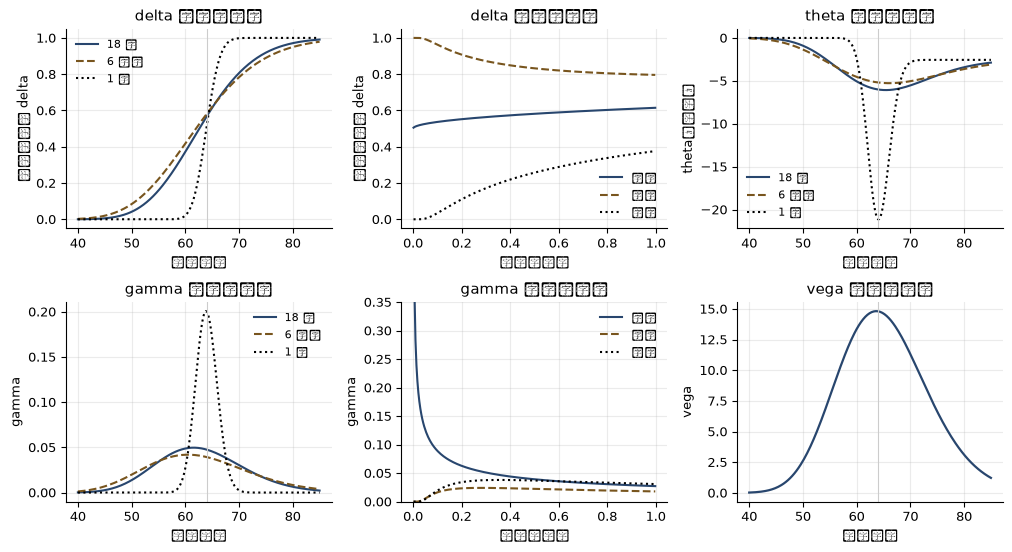

delta of the dealer's option                       0.5199   book       0.5199   ok
gamma of the dealer's option                       0.0489   book       0.0489   ok
theta of the dealer's option, per year            -5.8757   book      -5.8757   ok
gamma peaks at 61.6 on the grid, 61.55 in closed form, against a strike of 64
the grid finds the closed-form peak               61.6000   book      61.5535   ok
gamma peaks below the strike                       1.0000   book       1.0000   ok
at-the-money gamma grows into expiration           1.0000   book       1.0000   ok
out-of-the-money gamma collapses instead           1.0000   book       1.0000   ok


In [7]:
from math import pi


def npdf(x):
    return exp(-0.5 * x * x) / sqrt(2.0 * pi)


def d1_of(S, T, sig=SIGMA):
    return (log(S / K) + (r + 0.5 * sig * sig) * T) / (sig * sqrt(T))


def gamma_call(S, T, sig=SIGMA):
    return npdf(d1_of(S, T, sig)) / (S * sig * sqrt(T))


def theta_call(S, T, sig=SIGMA):
    d1 = d1_of(S, T, sig)
    return -S * npdf(d1) * sig / (2.0 * sqrt(T)) - r * K * exp(-r * T) * N(d1 - sig * sqrt(T))


def vega_call(S, T, sig=SIGMA):
    return S * sqrt(T) * npdf(d1_of(S, T, sig))


spots = [40.0 + 0.2 * i for i in range(226)]          # 40 to 85
lives = [0.002 + 0.004 * i for i in range(250)]       # a few days out to a year

fig, ax = plt.subplots(2, 3, figsize=(10.2, 5.6))

for T, c, ls, lab in ((T0, BLUE, "-", "18 周"), (0.5, AMBER, "--", "6 个月"),
                      (0.02, "black", ":", "1 周")):
    ax[0, 0].plot(spots, [delta(S, T) for S in spots], color=c, ls=ls, lw=1.5, label=lab)
    ax[1, 0].plot(spots, [gamma_call(S, T) for S in spots], color=c, ls=ls, lw=1.5, label=lab)
    ax[0, 2].plot(spots, [theta_call(S, T) for S in spots], color=c, ls=ls, lw=1.5, label=lab)
ax[0, 0].set_title("delta 对股票价格")
ax[0, 0].set_xlabel("股票价格"); ax[0, 0].set_ylabel("看涨期权的 delta")
ax[1, 0].set_title("gamma 对股票价格")
ax[1, 0].set_xlabel("股票价格"); ax[1, 0].set_ylabel("gamma")
ax[0, 2].set_title("theta 对股票价格")
ax[0, 2].set_xlabel("股票价格"); ax[0, 2].set_ylabel("theta（每年）")

for S, c, ls, lab in ((64.0, BLUE, "-", "平值"), (72.0, AMBER, "--", "实值"),
                      (56.0, "black", ":", "虚值")):
    ax[0, 1].plot(lives, [delta(S, T) for T in lives], color=c, ls=ls, lw=1.5, label=lab)
    ax[1, 1].plot(lives, [gamma_call(S, T) for T in lives], color=c, ls=ls, lw=1.5, label=lab)
ax[0, 1].set_title("delta 对剩余期限")
ax[0, 1].set_xlabel("距到期年数"); ax[0, 1].set_ylabel("看涨期权的 delta")
ax[1, 1].set_title("gamma 对剩余期限")
ax[1, 1].set_xlabel("距到期年数"); ax[1, 1].set_ylabel("gamma")
ax[1, 1].set_ylim(0, 0.35)

ax[1, 2].plot(spots, [vega_call(S, T0) for S in spots], color=BLUE, lw=1.6)
ax[1, 2].set_title("vega 对股票价格")
ax[1, 2].set_xlabel("股票价格"); ax[1, 2].set_ylabel("vega")

for a in ax.ravel():
    a.axvline(K, color="0.8", lw=0.8) if a.get_xlabel() == "股票价格" else None
for a in (ax[0, 0], ax[1, 0], ax[0, 1], ax[1, 1], ax[0, 2]):
    a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

# The three Greeks the chapter states for the dealer's option, at S = 63 and 18 weeks.
show("delta of the dealer's option", delta(S0, T0), 0.5199, 5e-4)
show("gamma of the dealer's option", gamma_call(S0, T0), 0.04886, 5e-5)
show("theta of the dealer's option, per year", theta_call(S0, T0), -5.8757, 5e-3)

# And the shape claims the panels are for, as claims rather than as quoted numbers.
# Gamma peaks a little BELOW the strike, and the offset has a closed form: setting the
# derivative of gamma to zero gives K exp(-(r + 3 sigma^2 / 2) T).
peak = spots[max(range(len(spots)), key=lambda i: gamma_call(spots[i], T0))]
peak_exact = K * exp(-(r + 1.5 * SIGMA ** 2) * T0)
print("gamma peaks at %.1f on the grid, %.2f in closed form, against a strike of %.0f"
      % (peak, peak_exact, K))
show("the grid finds the closed-form peak", peak, peak_exact, 0.3)
show("gamma peaks below the strike", float(peak_exact < K), 1.0, 0.5)
show("at-the-money gamma grows into expiration",
     float(gamma_call(K, 0.02) > gamma_call(K, T0)), 1.0, 0.5)
show("out-of-the-money gamma collapses instead",
     float(gamma_call(56.0, 0.02) < gamma_call(56.0, T0)), 1.0, 0.5)

## delta 作为乘数，以及期权的杠杆：例 18.1

delta 把股价的变动换算为期权价值的变动；与精确重新定价之差来自曲率，即式 (18.1)
中的 gamma 项。除以期权价值，得到期权的**弹性** $\Omega = S\Delta/f$：股价每变动 1%，
期权价值变动的百分比，也就是期权的杠杆。下图按本章的参数画出 $\Omega$ 随执行价的变化：
虚值看涨期权的杠杆最高。

call repriced at 64                                3.7385   book       3.7385   ok
exact rise for a $1 move                           0.5442   book       0.5442   ok
delta's prediction for a $1 move                   0.5199   book       0.5199   ok
gap: curvature                                     0.0242   book       0.0242   ok
gamma / 2, the second-order term                   0.0244   book       0.0244   ok
call repriced at 60                                1.8568   book       1.8568   ok
exact change for a $3 fall                        -1.3376   book      -1.3376   ok
delta's prediction for a $3 fall                  -1.5597   book      -1.5597   ok
elasticity Omega = S * delta / f                  10.2545   book      10.2500   ok
exact % rise for a 1% rise (to 63.63)             10.5565   book      10.5600   ok
call volatility, Omega * sigma, %                225.5987   book     226.0000   ok
Omega at strike 54                                 5.7066   book       5.7100   ok
Omeg

C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\817792437.py:29: UserWarning: Glyph 25191 (\N{CJK UNIFIED IDEOGRAPH-6267}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\817792437.py:29: UserWarning: Glyph 34892 (\N{CJK UNIFIED IDEOGRAPH-884C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\817792437.py:29: UserWarning: Glyph 20215 (\N{CJK UNIFIED IDEOGRAPH-4EF7}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\817792437.py:29: UserWarning: Glyph 24377 (\N{CJK UNIFIED IDEOGRAPH-5F39}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\817792437.py:29: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykernel_55

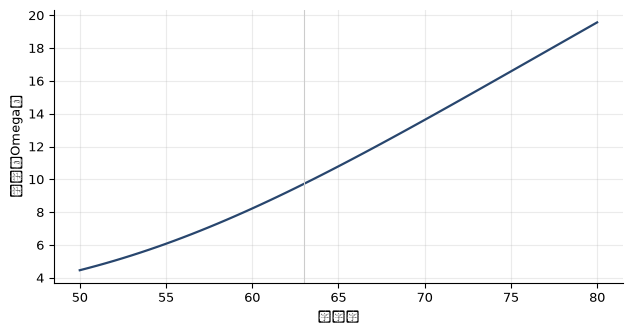

In [8]:
# Example 18.1: delta as a multiplier, and the call's elasticity (its leverage).
c0, d0 = price, delta(S0, T0)
up = bs_call(S0 + 1.0, K, T0, r, SIGMA) - c0
down = bs_call(S0 - 3.0, K, T0, r, SIGMA) - c0
show("call repriced at 64", bs_call(64.0, K, T0, r, SIGMA), 3.7385, 2e-5)
show("exact rise for a $1 move", up, 0.5442, 1e-4)
show("delta's prediction for a $1 move", d0, 0.5199, 1e-4)
show("gap: curvature", up - d0, 0.0242, 1e-4)
show("gamma / 2, the second-order term", gamma_call(S0, T0) / 2, 0.0244, 1e-4)
show("call repriced at 60", bs_call(60.0, K, T0, r, SIGMA), 1.8568, 2e-5)
show("exact change for a $3 fall", down, -1.3376, 1e-4)
show("delta's prediction for a $3 fall", -3 * round(d0, 4), -1.5597, 1e-4)

omega = S0 * d0 / c0
show("elasticity Omega = S * delta / f", omega, 10.25, 5e-4)
show("exact % rise for a 1% rise (to 63.63)", 100 * (bs_call(63.63, K, T0, r, SIGMA) / c0 - 1), 10.56, 5e-4)
show("call volatility, Omega * sigma, %", 100 * omega * SIGMA, 226, 3e-3)
for k, printed in ((54.0, 5.71), (74.0, 15.98)):
    om = S0 * delta(S0, T0, K=k) / bs_call(S0, k, T0, r, SIGMA)
    show("Omega at strike %g" % k, om, printed, 1e-3)

# Elasticity across strikes: out-of-the-money calls carry the most leverage.
strikes = [50.0 + 0.5 * i for i in range(61)]
fig, ax = plt.subplots()
ax.plot(strikes, [S0 * delta(S0, T0, K=k) / bs_call(S0, k, T0, r, SIGMA) for k in strikes],
        color=BLUE, lw=1.6)
ax.axvline(S0, color="0.8", lw=0.8)
ax.set_xlabel("执行价"); ax.set_ylabel("弹性（Omega）")
plt.tight_layout(); plt.show()


## 对冲的代价：图 18.1、18.3、18.8

同一个问题的三种读法。左图是对卖出的 100,000 份看涨期权的两种未对冲的应对：什么也不做，
以及直接买入股票。两者都不是对冲；而这张图是一张*盈亏*图（权利金已在所画的量里），
因此它的盈亏平衡点不是期权的盈亏平衡点。

中图说明为什么仅有 delta 对冲不够：期权价值是弯的，而它的 delta 近似是一条直线，
于是缺口朝两个方向都会张开。这个缺口就是 gamma，而无论股价朝哪边走它都是亏损。

右图是这套方案的成本对再平衡频率的关系，交易成本取本章的每笔交易金额的 0.10%，与表 18.7 相同。
再平衡越频繁，标准差越低而平均值越高，因此平均值加一个标准差有一个内部最小值，
在 100 次再平衡附近；这条曲线的实际含义全在于此。

C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\2201703411.py:40: UserWarning: Glyph 21040 (\N{CJK UNIFIED IDEOGRAPH-5230}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\2201703411.py:40: UserWarning: Glyph 26399 (\N{CJK UNIFIED IDEOGRAPH-671F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\2201703411.py:40: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\2201703411.py:40: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykernel_55748\2201703411.py:40: UserWarning: Glyph 32929 (\N{CJK UNIFIED IDEOGRAPH-80A1}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\wsuo\AppData\Local\Temp\ipykern

C:\Users\wsuo\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 30408 (\N{CJK UNIFIED IDEOGRAPH-76C8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\wsuo\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20111 (\N{CJK UNIFIED IDEOGRAPH-4E8F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\wsuo\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21315 (\N{CJK UNIFIED IDEOGRAPH-5343}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\wsuo\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 32654 (\N{CJK UNIFIED IDEOGRAPH-7F8E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\wsuo\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20803

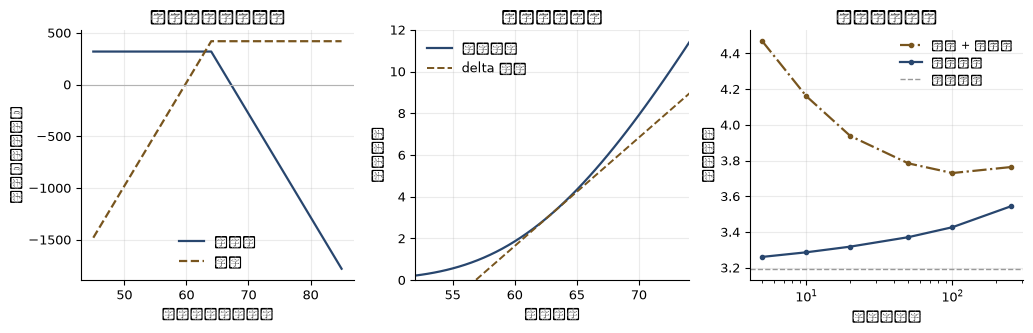

按平均加标准差计，成本最低的再平衡频率：期权存续期内 100 次
cheapest at 100 rebalances, as in Table 18.7         1.0000   book       1.0000   ok
n =   5: mean + s.d., Table 18.7                   4.4684   book       4.4552   ok
n =  10: mean + s.d., Table 18.7                   4.1608   book       4.1560   ok
n =  20: mean + s.d., Table 18.7                   3.9378   book       3.9370   ok
n =  50: mean + s.d., Table 18.7                   3.7843   book       3.7760   ok
n = 100: mean + s.d., Table 18.7                   3.7303   book       3.7242   ok
n = 250: mean + s.d., Table 18.7                   3.7636   book       3.7689   ok


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(10.4, 3.4))

# --- Figure 18.1: the two unhedged responses, in thousands of dollars
ST = [45.0 + 0.5 * i for i in range(81)]
naked = [(premium - max(s - K, 0.0) * N_OPT) / 1000.0 for s in ST]
covered = [(premium - max(s - K, 0.0) * N_OPT + (s - S0) * N_OPT) / 1000.0 for s in ST]
ax[0].plot(ST, naked, color=BLUE, lw=1.6, label="裸头寸")
ax[0].plot(ST, covered, color=AMBER, lw=1.6, ls="--", label="备兑")
ax[0].axhline(0.0, color="0.7", lw=0.8)
ax[0].set_title("两种未对冲的应对")
ax[0].set_xlabel("到期时的股票价格"); ax[0].set_ylabel("盈亏（千美元）")
ax[0].legend(frameon=False)

# --- Figure 18.3: the option's curve against its tangent at 63
tangent = [price + delta(S0, T0) * (s - S0) for s in ST]
curve = [bs_call(s, K, T0, r, SIGMA) for s in ST]
ax[1].plot(ST, curve, color=BLUE, lw=1.6, label="期权价值")
ax[1].plot(ST, tangent, color=AMBER, lw=1.4, ls="--", label="delta 近似")
ax[1].set_xlim(52, 74); ax[1].set_ylim(0, 12)
ax[1].set_title("缺口就是曲率")
ax[1].set_xlabel("股票价格"); ax[1].set_ylabel("期权价值")
ax[1].legend(frameon=False)

# --- Figure 18.8: cost against rebalancing frequency, with the chapter's trading cost
COST_RATE = 0.0010                                     # 每笔交易金额的 0.10%
counts = [5, 10, 20, 50, 100, 250]
TABLE_18_7 = {5: 4.4552, 10: 4.1560, 20: 3.9370, 50: 3.7760, 100: 3.7242, 250: 3.7689}
means, totals = [], []
for n_reb in counts:
    c = hedge_cost_mc(n_reb, n_paths=10_000, cost_rate=COST_RATE)
    means.append(c.mean())
    totals.append(c.mean() + c.std())
ax[2].plot(counts, totals, color=AMBER, lw=1.6, ls="-.", marker="o", ms=3, label="平均 + 标准差")
ax[2].plot(counts, means, color=BLUE, lw=1.6, marker="o", ms=3, label="平均成本")
ax[2].axhline(price, color="0.6", lw=1.0, ls="--", label="公式取值")
ax[2].set_xscale("log")
ax[2].set_title("频率上的权衡")
ax[2].set_xlabel("再平衡次数"); ax[2].set_ylabel("对冲成本")
ax[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

best = counts[min(range(len(totals)), key=lambda i: totals[i])]
print("按平均加标准差计，成本最低的再平衡频率：期权存续期内 %d 次" % best)
show("cheapest at 100 rebalances, as in Table 18.7", float(best == 100), 1.0, 0.5)
for n_reb, tot in zip(counts, totals):
    show("n = %3d: mean + s.d., Table 18.7" % n_reb, tot, TABLE_18_7[n_reb], 0.01)